In [ ]:
# Import general utilities
import numpy as np
import matplotlib.pyplot as plt

# Import TDA utilities
from ripser import Rips
from tadasets import torus, sphere
from persim.landscapes import PersLandscapeExact
from persim.landscapes import plot_landscape_simple
from persim.landscapes import PersistenceLandscaper
from persim import plot_diagrams

# Import Scikit-Learn tools
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn import metrics
from sklearn.model_selection import train_test_split

rips = Rips(maxdim=2)

In [ ]:

landscapes_torus = []
landscapes_sphere = []

for i in range(100):
    # Resample data
    _data_torus = torus(n=100, c=2, a=1)
    _data_sphere = sphere(n=100, r=2)

    # Compute persistence diagrams
    dgm_torus = rips.fit_transform(_data_torus)

    # Instantiate persistence landscape transformer
    torus_landscaper = PersistenceLandscaper(
        hom_deg=1, start=0, stop=2.0, num_steps=500, flatten=True
    )

    # Compute flattened persistence landscape
    torus_flat = torus_landscaper.fit_transform(dgm_torus)

    landscapes_torus.append(torus_flat)

    # Compute persistence diagrams
    dgm_sphere = rips.fit_transform(_data_sphere)

    # Instantiate persistence landscape transformer
    sphere_landscaper = PersistenceLandscaper(
        hom_deg=1, start=0, stop=2.0, num_steps=500, flatten=True
    )

    # Compute flattened persistence landscape
    sphere_flat = sphere_landscaper.fit_transform(dgm_sphere)

    landscapes_sphere.append(sphere_flat)

landscapes_torus = np.array(landscapes_torus, dtype=object)
landscapes_sphere = np.array(landscapes_sphere, dtype=object)
print("Torus:", np.shape(landscapes_torus))
print("Sphere:", np.shape(landscapes_sphere))

In [ ]:
# Find maximal length
u = np.max([len(a) for a in landscapes_torus])
v = np.max([len(a) for a in landscapes_sphere])

w = np.max([u, v])

# Instantiate zero-padded arrays
ls_torus = np.zeros((100, w))
ls_sphere = np.zeros((100, w))

# Populate arrays
for i in range(len(landscapes_torus)):
    ls_torus[i, 0 : len(landscapes_torus[i])] = landscapes_torus[i]
    ls_sphere[i, 0 : len(landscapes_sphere[i])] = landscapes_sphere[i]


print("Torus:", ls_torus.shape)
print("Sphere:", ls_sphere.shape)

In [ ]:
# Instantiate PCA solver
pca_torus = PCA(n_components=2)

# Compute PCA and store transformed data
transformed_torus = pca_torus.fit_transform(ls_torus)

# Define components
comp_torus = pca_torus.components_

# Instantiate PCA solver
pca_sphere = PCA(n_components=2)

# Compute PCA and store transformed data
transformed_sphere = pca_sphere.fit_transform(ls_sphere)

# Define components
comp_sphere = pca_sphere.components_

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(transformed_torus[:, 0], transformed_torus[:, 1], label="Torus PCA Projection", alpha=0.6, edgecolor="black")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection of Torus Persistence Landscapes")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans

# Perform K-means clustering on the transformed torus data
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10) # Set n_init to suppress warning
clusters = kmeans.fit_predict(transformed_torus)

# Visualize the clusters
plt.figure(figsize=(8, 6))
plt.scatter(transformed_torus[:, 0], transformed_torus[:, 1], c=clusters, cmap='viridis', s=50, alpha=0.8)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering on Torus PCA Projection (k=2)")
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans

# Calculate sum of squared distances for different number of clusters
ssd = []
K_range = range(1, 11) # Test k from 1 to 10

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # Set n_init to suppress warning
    kmeans.fit(transformed_torus)
    ssd.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(10, 6))
plt.plot(K_range, ssd, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Sum of Squared Distances (Inertia)')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

In [ ]:
print("Singular values for torus dataset:", pca_torus.singular_values_)
print("Singular values for sphere dataset:", pca_sphere.singular_values_)

In [ ]:
# Plot projection of data onto the first two principal components
plt.figure(figsize=(10, 8))
plt.scatter(comp_sphere[0], comp_sphere[1], label="Sphere", alpha=0.4)
for i in range(len(comp_sphere[0])):
    plt.quiver(0, 0, comp_sphere[0, i], comp_sphere[1, i], angles='xy', scale_units='xy', scale=1, color='blue', alpha=0.3, width=0.002)


plt.scatter(comp_torus[0], comp_torus[1], label="Torus", alpha=0.4)
for i in range(len(comp_torus[0])):
    plt.quiver(0, 0, comp_torus[0, i], comp_torus[1, i], angles='xy', scale_units='xy', scale=1, color='red', alpha=0.3, width=0.002)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Components with Vectors from Origin")
plt.legend()
plt.grid(True)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.show()

## Comparing Loading Components

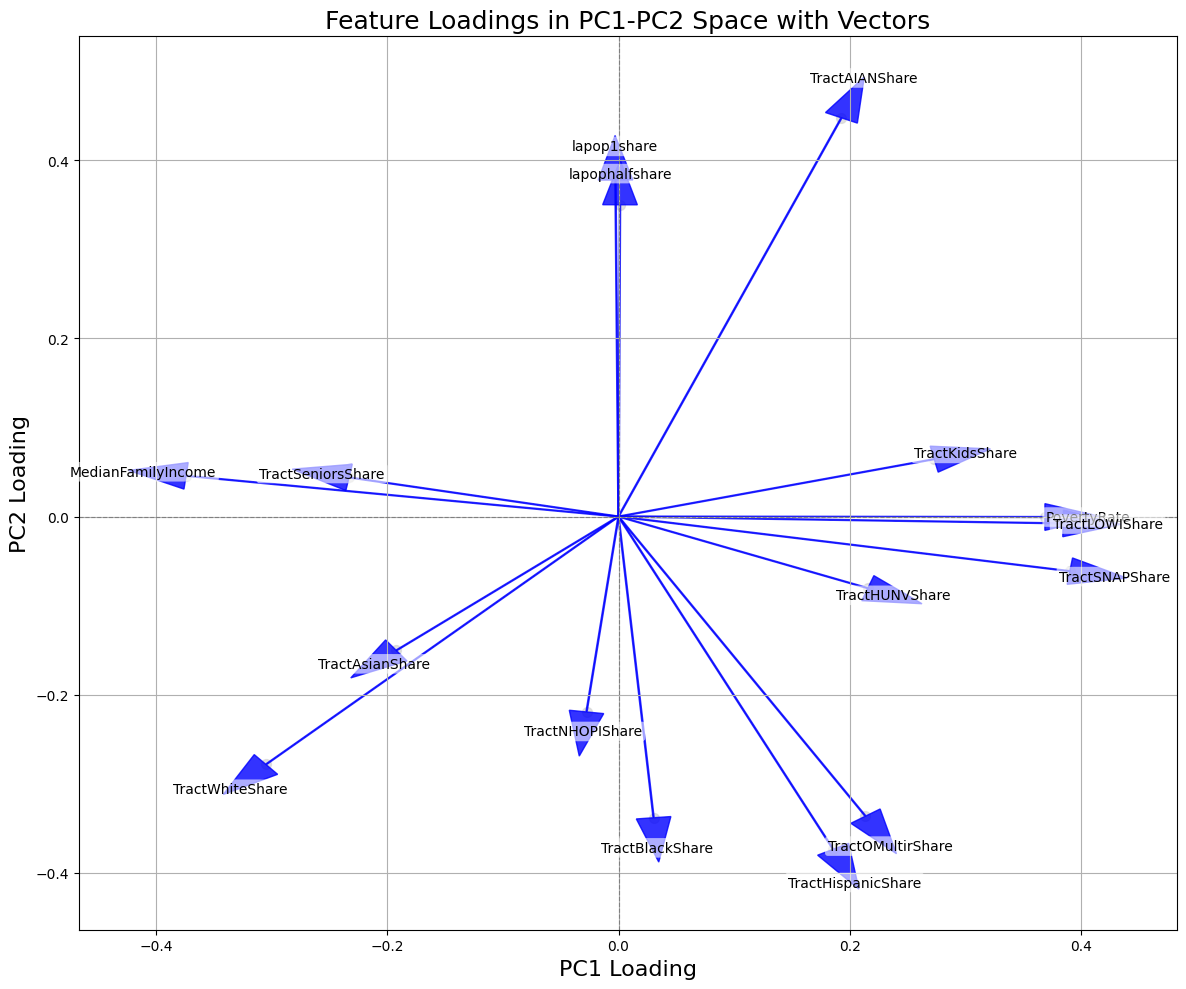